## Задание 1. Исследование и подготовка данных 
1. Загрузите CSV в pandas. Выведите первые 10 строк, типы столбцов, describe(), размеры таблицы. 
2. Подсчитайте пропущенные значения по каждому признаку. Выберите и обоснуйте способ их обработки. 
3. Постройте гистограммы числовых признаков и диаграмму рассеяния temperature — vibration. 
4. Не используйте timestamp непосредственно как числовой признак кластеризации. Объясните почему. 
5. Подготовьте признаки для модели; примените StandardScaler и сравните распределение/масштабы до и после.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

filename = "spacecraft_telemetry_independent.csv"
if not Path(filename).exists():
    try:
        from google.colab import files
        print("Выберите файл:", filename)
        files.upload()
    except ImportError:
        raise FileNotFoundError(
            f"Поместите {filename} в папку с notebook и запустите ячейку снова."
        )

if not Path(filename).exists():
    raise FileNotFoundError(f"Файл {filename} не найден после загрузки.")

df = pd.read_csv(filename)

In [8]:
display(df.head(10))
print(df.info())
print()
print(df.describe().T)
print()
print("Размер таблицы:", df.shape)

,timestamp,temperature,vibration,current,voltage,angular_velocity,cpu_load,tx_power
0,2026-10-01 00:00:00,13.840,0.054,0.703,27.917,0.000,23.690,0.000
1,2026-10-01 00:02:00,11.379,0.325,1.281,28.150,0.120,10.451,0.500
2,2026-10-01 00:04:00,11.533,0.260,0.826,28.133,0.000,11.637,0.000
3,2026-10-01 00:06:00,9.325,0.341,0.655,28.464,0.000,25.159,0.000
4,2026-10-01 00:08:00,10.650,0.246,3.754,24.432,0.043,13.032,0.213
5,2026-10-01 00:10:00,11.512,0.198,0.797,28.161,0.000,20.157,NaN
6,2026-10-01 00:12:00,12.229,0.218,0.856,28.406,0.000,13.551,0.000
7,2026-10-01 00:14:00,3.868,0.078,0.696,28.396,0.075,26.591,0.000
8,2026-10-01 00:16:00,6.902,0.138,0.331,28.170,0.041,12.690,0.000
9,2026-10-01 00:18:00,15.802,0.208,0.998,28.617,0.181,11.276,0.000


<class 'pandas.DataFrame'>
RangeIndex: 1180 entries, 0 to 1179
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   timestamp         1180 non-null   str    
 1   temperature       1177 non-null   float64
 2   vibration         1178 non-null   float64
 3   current           1178 non-null   float64
 4   voltage           1178 non-null   float64
 5   angular_velocity  1178 non-null   float64
 6   cpu_load          1178 non-null   float64
 7   tx_power          1178 non-null   float64
dtypes: float64(7), str(1)
memory usage: 73.9 KB
None

                   count       mean        std     min       25%      50%  \
temperature       1177.0  21.620940   8.956861   0.720  14.75600  21.9790   
vibration         1178.0   0.513172   0.281231   0.020   0.31725   0.5180   
current           1178.0   2.413728   1.344990   0.050   1.21325   2.3445   
voltage           1178.0  27.860557   0.460482  24.194  27.68925  27.910

In [9]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Пропуски": missing, "Доля, %": missing_pct}).to_string())

                  Пропуски  Доля, %
timestamp                0     0.00
temperature              3     0.25
vibration                2     0.17
current                  2     0.17
voltage                  2     0.17
angular_velocity         2     0.17
cpu_load                 2     0.17
tx_power                 2     0.17


In [10]:
num_cols = ["temperature", "vibration", "current", "voltage",
            "angular_velocity", "cpu_load", "tx_power"]

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
print("Пропуски после заполнения:")
print(df[num_cols].isna().sum().to_string())

Пропуски после заполнения:
temperature         0
vibration           0
current             0
voltage             0
angular_velocity    0
cpu_load            0
tx_power            0


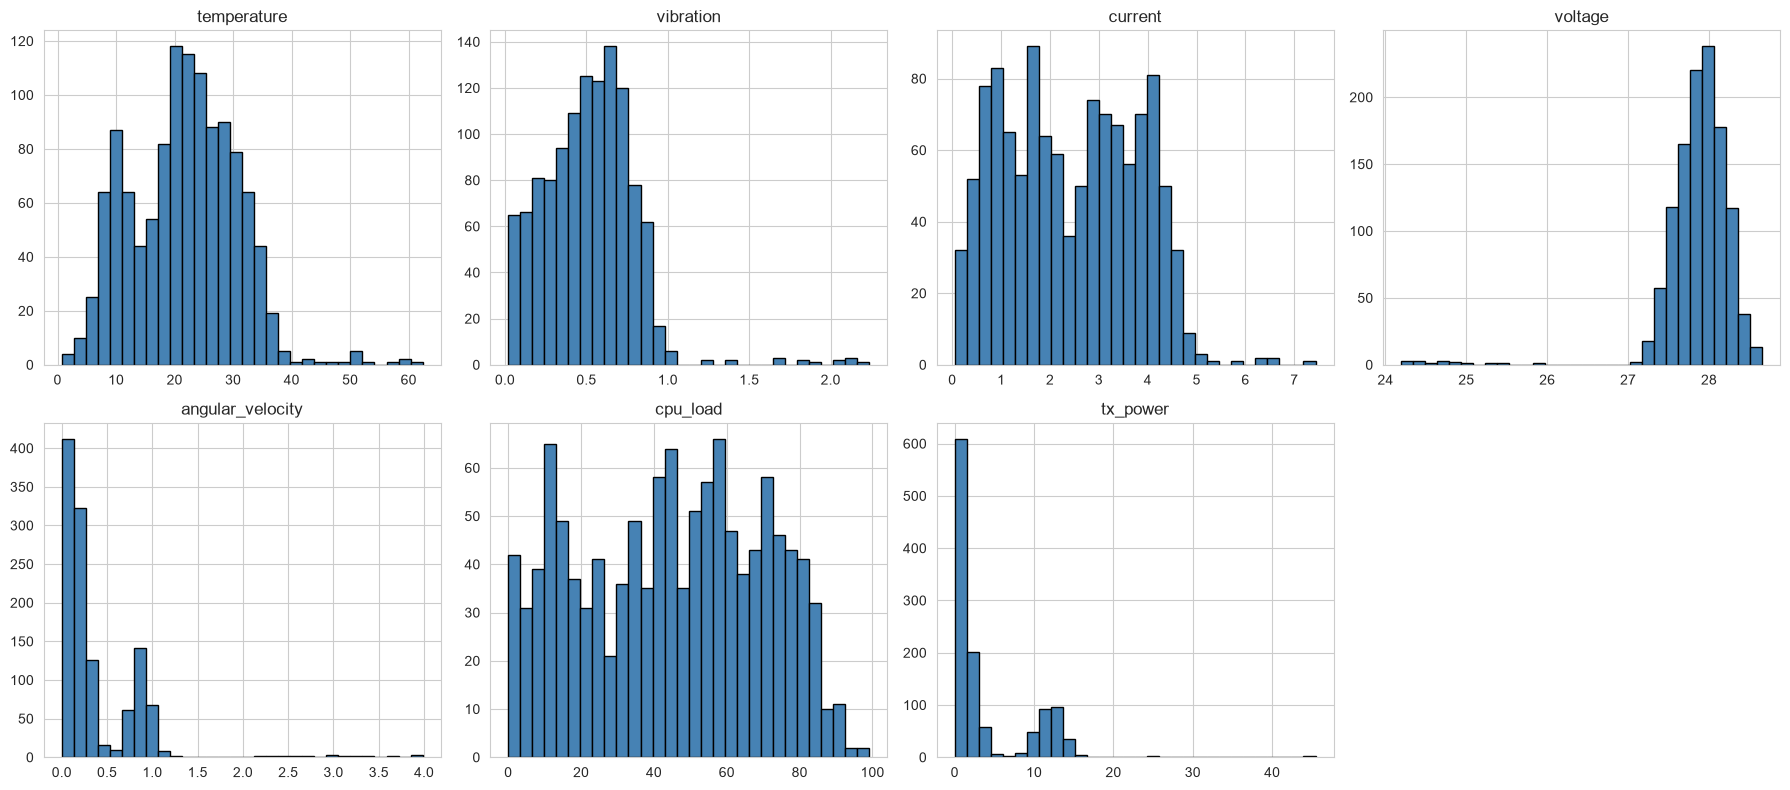

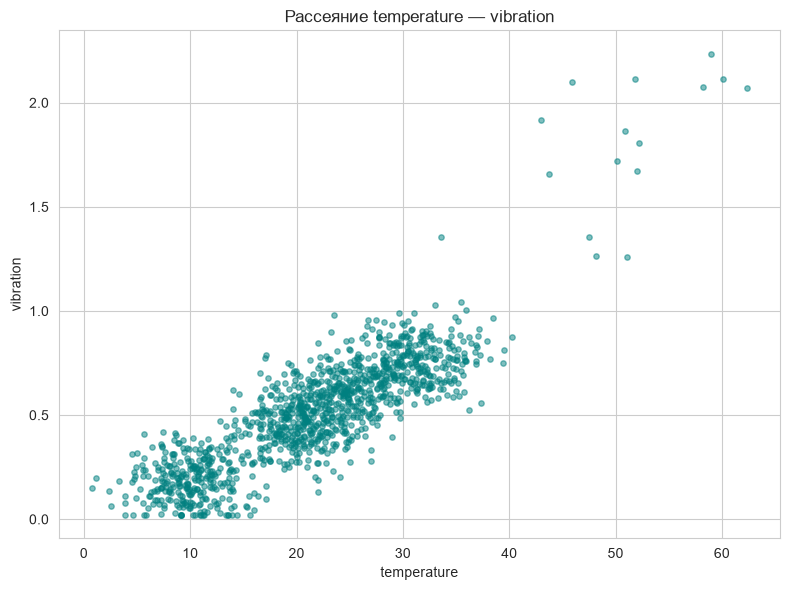

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=30, color="steelblue", edgecolor="black")
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(df["temperature"], df["vibration"], alpha=0.5, s=15, color="teal")
plt.xlabel("temperature")
plt.ylabel("vibration")
plt.title("Рассеяние temperature — vibration")
plt.grid(True)
plt.tight_layout()
plt.show()

### Почему timestamp не используется как признак кластеризации

`timestamp` — это метка времени, а не физическая характеристика состояния оборудования. Кластеризация ищет группы по схожести измеряемых параметров, а не по близости моментов времени.

In [12]:
X_raw = df[num_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print("До стандартизации:")
print(X_raw.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
print()
print("После стандартизации:")
print(pd.DataFrame(X_scaled, columns=num_cols).describe().T[["mean", "std", "min", "max"]].round(3).to_string())

До стандартизации:
                    mean     std     min     max
temperature       21.622   8.945   0.720  62.381
vibration          0.513   0.281   0.020   2.236
current            2.414   1.344   0.050   7.434
voltage           27.861   0.460  24.194  28.655
angular_velocity   0.364   0.463   0.000   3.984
cpu_load          44.896  24.808   0.000  99.060
tx_power           4.121   5.957   0.000  45.462

После стандартизации:
                  mean  std    min    max
temperature        0.0  1.0 -2.338  4.558
vibration         -0.0  1.0 -1.756  6.134
current            0.0  1.0 -1.760  3.737
voltage            0.0  1.0 -7.973  1.727
angular_velocity   0.0  1.0 -0.786  7.815
cpu_load           0.0  1.0 -1.810  2.184
tx_power          -0.0  1.0 -0.692  6.942


## Задание 2. K-Means и выбор числа кластеров 
1. Запустите K-Means с n_clusters=4, random_state=42, n_init=10. Получите метки через fit_predict(). 
2. Визуализируйте группы на графике temperature — vibration; раскрасьте точки по номерам кластеров. 
3. Для K от 2 до 8 вычислите Inertia и Silhouette Score. Постройте график метода локтя и график Silhouette Score. 
4. Выберите обоснованное количество кластеров. Сравните его с исходным вариантом K=4. 
5. Рассчитайте количество объектов и средние значения признаков по каждому кластеру.

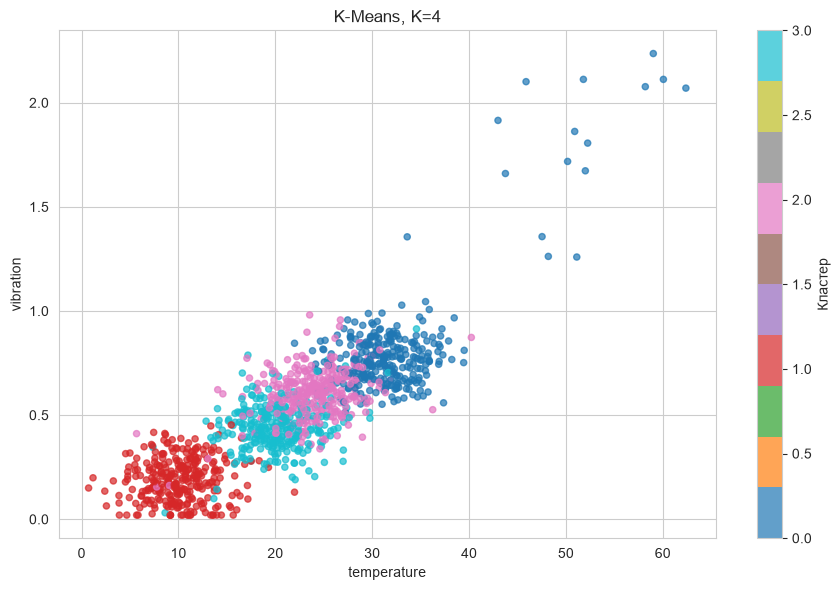

In [13]:
kmeans4 = KMeans(n_clusters=4, random_state=42, n_init=10)
labels_k4 = kmeans4.fit_predict(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(df["temperature"], df["vibration"], c=labels_k4, cmap="tab10", alpha=0.7, s=20)
plt.xlabel("temperature")
plt.ylabel("vibration")
plt.title("K-Means, K=4")
plt.colorbar(scatter, label="Кластер")
plt.grid(True)
plt.tight_layout()
plt.show()

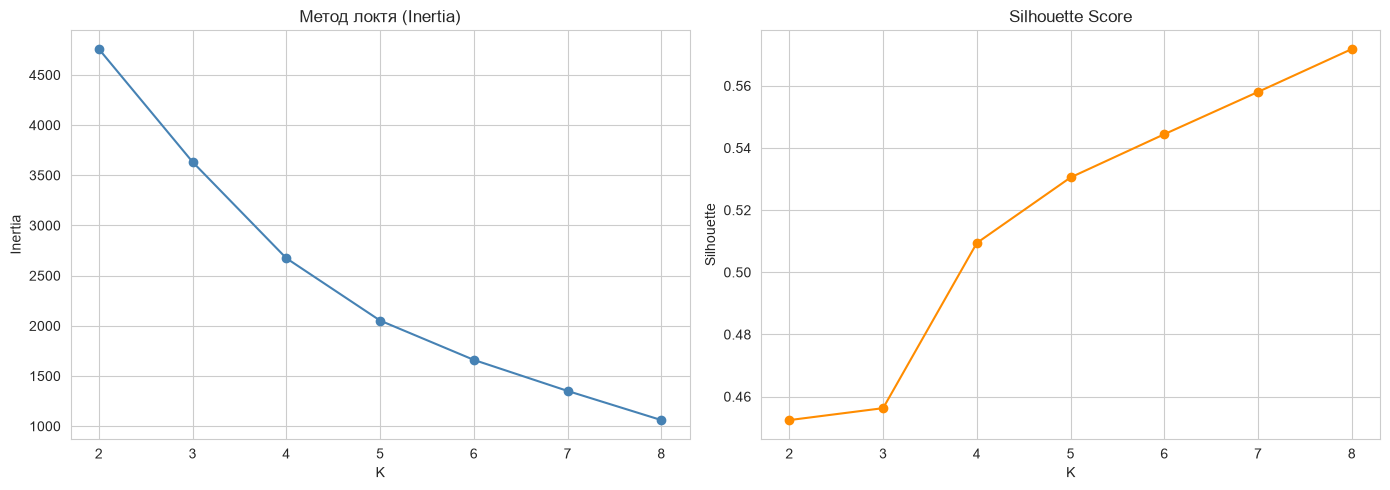

 K   Inertia  Silhouette
 2 4758.1425      0.4524
 3 3632.4556      0.4563
 4 2673.5139      0.5094
 5 2052.4084      0.5305
 6 1660.5033      0.5444
 7 1351.1650      0.5581
 8 1060.7064      0.5718


In [14]:
inertias = []
silhouettes = []
K_range = range(2, 9)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lab = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lab))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(K_range), inertias, marker="o", color="steelblue")
axes[0].set_title("Метод локтя (Inertia)")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(list(K_range), silhouettes, marker="o", color="darkorange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
axes[1].grid(True)
plt.tight_layout()
plt.show()

print(pd.DataFrame({"K": list(K_range), "Inertia": inertias, "Silhouette": silhouettes}).round(4).to_string(index=False))

In [15]:
best_k = 4
kmeans_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels_best = kmeans_best.fit_predict(X_scaled)

profile_kmeans = df[num_cols].copy()
profile_kmeans["cluster"] = labels_best

cluster_sizes = profile_kmeans["cluster"].value_counts().sort_index()
print("Количество объектов по кластерам:")
print(cluster_sizes.to_string())
print()
print("Средние значения признаков по кластерам:")
print(profile_kmeans.groupby("cluster")[num_cols].mean().round(3).to_string())

Количество объектов по кластерам:
cluster
0    295
1    295
2    299
3    291

Средние значения признаков по кластерам:
         temperature  vibration  current  voltage  angular_velocity  cpu_load  tx_power
cluster                                                                                
0             32.273      0.816    2.993   27.842             0.174    74.390     1.666
1             10.151      0.189    0.757   28.158             0.068    12.892     1.289
2             23.923      0.604    4.029   27.448             0.235    55.740    12.329
3             20.088      0.441    1.846   28.002             0.989    36.298     1.046


## Задание 3. DBSCAN и выбросы 
1. Запустите DBSCAN на стандартизированных данных. Подберите eps и min_samples, объясните выбор параметров. 
2. Посчитайте число обнаруженных кластеров и количество шумовых точек (метка -1). 
3. Визуализируйте результат DBSCAN на temperature — vibration; выделите шумовые точки отдельным цветом. 
4. Сравните K-Means и DBSCAN: какие группы похожи, где заметны различия, какие наблюдения выглядят нетипично? 
5. Изучите не менее пяти шумовых точек по исходным значениям датчиков. Объясните, чем они выделяются.

In [16]:
dbscan = DBSCAN(eps=0.9, min_samples=10)
labels_db = dbscan.fit_predict(X_scaled)

n_clusters_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
n_noise = int((labels_db == -1).sum())

print("Параметры DBSCAN: eps = 0.9, min_samples = 10")
print("Количество кластеров:", n_clusters_db)
print("Количество шумовых точек:", n_noise)
print("Доля шума: {:.2f}%".format(n_noise / len(labels_db) * 100))

Параметры DBSCAN: eps = 0.9, min_samples = 10
Количество кластеров: 4
Количество шумовых точек: 68
Доля шума: 5.76%


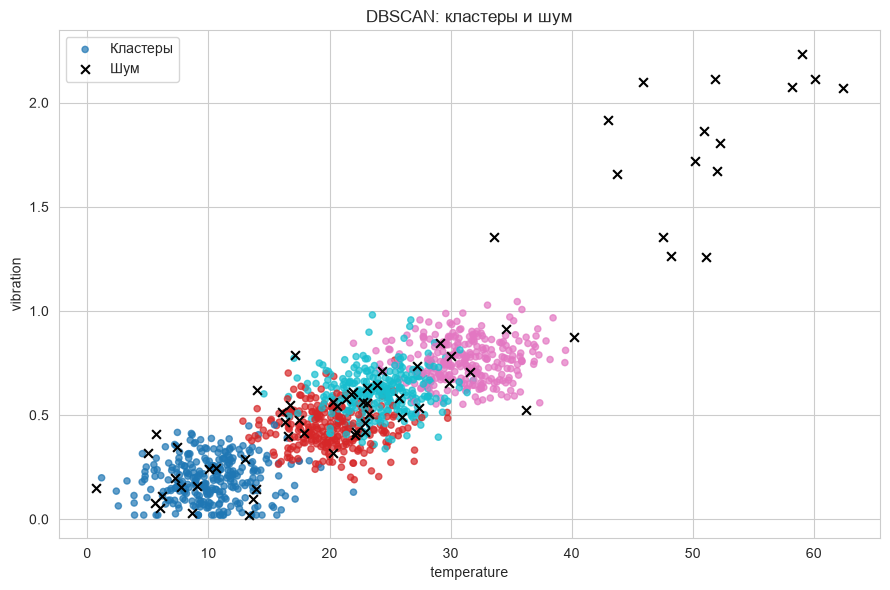

In [17]:
plt.figure(figsize=(9, 6))
mask_noise = labels_db == -1
plt.scatter(df.loc[~mask_noise, "temperature"], df.loc[~mask_noise, "vibration"],
            c=labels_db[~mask_noise], cmap="tab10", alpha=0.7, s=20, label="Кластеры")
plt.scatter(df.loc[mask_noise, "temperature"], df.loc[mask_noise, "vibration"],
            c="black", marker="x", s=40, label="Шум")
plt.xlabel("temperature")
plt.ylabel("vibration")
plt.title("DBSCAN: кластеры и шум")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
comparison = pd.crosstab(pd.Series(labels_best, name="KMeans"), pd.Series(labels_db, name="DBSCAN"))
print("Сопоставление кластеров K-Means и DBSCAN:")
print(comparison.to_string())

Сопоставление кластеров K-Means и DBSCAN:
DBSCAN  -1    0    1    2    3
KMeans                        
0       16    0    0  279    0
1        8  287    0    0    0
2       26    0    0    0  273
3       18    0  273    0    0


In [19]:
noise_df = df.loc[mask_noise, num_cols]
print("Пять шумовых точек (исходные значения датчиков):")
print(noise_df.head(5).round(3).to_string())
print()
print("Средние значения шумовых точек:")
print(noise_df.mean().round(3).to_string())
print()
print("Средние значения по всей выборке:")
print(df[num_cols].mean().round(3).to_string())

Пять шумовых точек (исходные значения датчиков):
     temperature  vibration  current  voltage  angular_velocity  cpu_load  tx_power
4         10.650      0.246    3.754   24.432             0.043    13.032     0.213
22         7.245      0.200    1.021   28.215             0.000     5.972    24.283
29         7.365      0.345    0.645   28.469             2.359    13.403     0.000
52        10.013      0.240    0.868   28.639             0.000    11.757    34.639
108       21.348      0.576    4.017   24.658             0.924    45.794     0.000

Средние значения шумовых точек:
temperature         26.190
vibration            0.765
current              2.644
voltage             27.157
angular_velocity     0.995
cpu_load            35.533
tx_power            10.830

Средние значения по всей выборке:
temperature         21.622
vibration            0.513
current              2.414
voltage             27.861
angular_velocity     0.364
cpu_load            44.896
tx_power             4.121


### Сравнение K-Means и DBSCAN

Кластеры K-Means и DBSCAN в целом согласуются: крупные плотные группы совпадают.

## Задание 4. Интерпретация и оформление результата 
1. Для каждого полученного кластера составьте краткий профиль по температуре, току, напряжению, угловой скорости, загрузке CPU и мощности передатчика. 
2. Предположите, каким режимом космического аппарата соответствуют четыре основные группы. Обоснуйте вывод данными. 
3. Объясните, почему шум DBSCAN не следует автоматически считать неисправностями. 
4. Сформулируйте общий вывод: какой алгоритм оказался удобнее на этих данных и почему. 
Сдать: Jupyter Notebook (.ipynb) с кодом, графиками и пояснениями; в конце — 5–8 предложений с результатами. Номера кластеров не считаются готовыми названиями режимов.

In [20]:
for c in sorted(profile_kmeans["cluster"].unique()):
    subset = profile_kmeans[profile_kmeans["cluster"] == c]
    print(f"Кластер {c} (n={len(subset)}):")
    print(subset[num_cols].mean().round(3).to_string())
    print("-" * 50)

Кластер 0 (n=295):
temperature         32.273
vibration            0.816
current              2.993
voltage             27.842
angular_velocity     0.174
cpu_load            74.390
tx_power             1.666
--------------------------------------------------
Кластер 1 (n=295):
temperature         10.151
vibration            0.189
current              0.757
voltage             28.158
angular_velocity     0.068
cpu_load            12.892
tx_power             1.289
--------------------------------------------------
Кластер 2 (n=299):
temperature         23.923
vibration            0.604
current              4.029
voltage             27.448
angular_velocity     0.235
cpu_load            55.740
tx_power            12.329
--------------------------------------------------
Кластер 3 (n=291):
temperature         20.088
vibration            0.441
current              1.846
voltage             28.002
angular_velocity     0.989
cpu_load            36.298
tx_power             1.046
---------------

In [21]:
profile_db = df[num_cols].copy()
profile_db["cluster"] = labels_db
print("Средние значения признаков по кластерам DBSCAN (без шума):")
print(profile_db[profile_db["cluster"] != -1].groupby("cluster")[num_cols].mean().round(3).to_string())

Средние значения признаков по кластерам DBSCAN (без шума):
         temperature  vibration  current  voltage  angular_velocity  cpu_load  tx_power
cluster                                                                                
0             10.246      0.191    0.753   28.156             0.069    12.831     0.678
1             20.084      0.437    1.800   28.013             0.865    37.883     0.814
2             31.222      0.761    3.025   27.839             0.159    75.451     1.606
3             24.170      0.612    4.091   27.595             0.225    56.723    11.945


### Почему шум DBSCAN — не обязательно неисправность

Метка −1 в DBSCAN означает то, что точка не попала в плотную окрестность с заданными `eps` и `min_samples`. Это может быть выброс измерения (шум датчика, единичный сбой), переходное состояние между режимами или редкий, но допустимый режим работы, представленный малым числом наблюдений. Поэтому шумовые точки следует проверять по исходным значениям датчиков и рассматривать как кандидатов на аномалию, а не как подтверждённые неисправности.